### Gestion de code Lucas MATHIEU, Antoine AFLALO, Mathys BOVENZI
code Python, Arduino

In [ ]:
!pip install pyserial

import serial

import time
import matplotlib.pyplot as plt


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [4]:
# step 7 - paramètre de l'experéience 
NB_ESSAIS = 10
DUREE_ESSAI = 10
PAUSE_RESET = 2
ATTENDRE_ENTREE = True
PREFIXE = "essai"



# configurer  le port serie 
serialPort = serial.Serial() # créer une instance, création et configuration port série
serialPort.baudrate = 115200 # vitesse 
serialPort.parity = serial.PARITY_NONE # aucun bit de parité 
serialPort.bytesize = serial.EIGHTBITS # taille d'un caractère : 8 bits 
serialPort.stopbits = serial.STOPBITS_ONE # 1 bit de stop 
serialPort.port = "/dev/cu.usbmodem34B7DA6494902" # nom/chemin du port série à utiliser


# ouvir le port serie 
serialPort.open() # active la liaison série avec la carte
time.sleep(PAUSE_RESET) # step 7

tousLesEssais = {}

for numEssai in range(1, NB_ESSAIS + 1):

    if ATTENDRE_ENTREE:
        input(f"Essai {numEssai} / {NB_ESSAIS} - appuie sur Entrée pour démarrer")
    print(f"Essai {numEssai} / {NB_ESSAIS} en cours...")

    serialPort.reset_input_buffer()

    # envoyer le code 'r' soit 114
    cmd = 'r' # caractère à envoyer pour démarrer la carte 
    serialPort.write(cmd.encode(encoding = "ascii")) # conversion en octer ASCII puis envoi sur le port série
    serialPort.flush() # Etape 4 - s'arruer que la commande 'r' est bien arrivé

    # on laisse tourner l'essai pendant envrion 10sec
    tStart = time.perf_counter() # instant de référence
    tEcoule = 0     # initalise à 0 seconde

    times = [] # endroit ou se stocker le temps
    bruts = [] # step 5 - stockage valeurs brutes FSR

    while tEcoule < 10: # si le temps tEcoule est inférieur à 10, cela continu dans la boucle
        tEcoule = time.perf_counter() - tStart # Quand tEcoule est = à 10, cela s'arrete
    
        ligne = serialPort.readline() # Etape 4 - lire la ligne envoyé par l'Arduino
        if ligne :
            try :
                # valeur_us = int(ligne.decode(encoding="ascii").strip())
                # times.append(valeur_us / 1000000) # Etape 4 - accumlulation en seconde car en micro sur Arduino
                morceaux = ligne.decode(encoding="ascii").strip().split(";") # Step 5 - "1234567;400" -> ["1234567", "400"]
                valeur_us = int(morceaux[0])                                 # Step 5 - le temps en µs
                brut = int(morceaux[1])                                      # Step 5 - la valeur brute du FSR
                times.append(valeur_us / 1000000)                            # Step 5 - temps en secondes
                bruts.append(brut)                                           # Step 5
            except (ValueError, IndexError): # Step 5 - IndexError si une ligne est incomplète
                pass
        
    

    # envoyer le code 's' soit 115 : déclanche le software reset côté Arduino
    cmd = 's' # caractère à envoyer pour déclancher le reset 
    serialPort.write(cmd.encode(encoding = "ascii", errors="ignore")) # conversion en octet ASCII puis envoi sur le port série 
    serialPort.flush() # Etape 4 - s'arruer que la commande 's' est bien arrivé

    tousLesEssais[numEssai] = (times, bruts)
    
    time.sleep(PAUSE_RESET) # Step 7 - laisser l'Arduino redémarrer avant l'essai suivant
    
    
    
# fermer le port serie 
serialPort.close() # libère le port série
print("Acquisition terminée")

 


Essai 1 / 10 en cours...
Essai 2 / 10 en cours...
Essai 3 / 10 en cours...
Essai 4 / 10 en cours...
Essai 5 / 10 en cours...
Essai 6 / 10 en cours...
Essai 7 / 10 en cours...
Essai 8 / 10 en cours...
Essai 9 / 10 en cours...
Essai 10 / 10 en cours...
Acquisition terminée


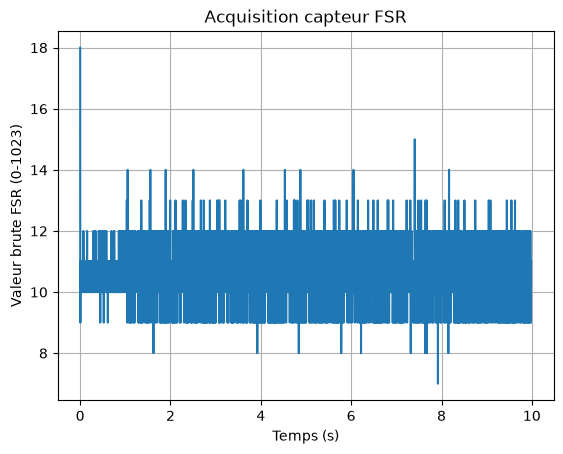

In [5]:
# Step 5 - tracer l'acquisition
plt.plot(times, bruts)                         
plt.xlabel("Temps (s)")                   
plt.ylabel("Valeur brute FSR (0-1023)")        
plt.title("Acquisition capteur FSR")          
plt.grid(True)                                
plt.show()  


### Ajouter une IHM

In [8]:
import os
print(os.getcwd())

/Users/lucas1/Desktop/School/AMU - STAPS/M2 S1/Cours/1. Génération de Code/codeManagementGIT


In [ ]:

"""
FIEC30EM - Projet FSR - Étape 8 : IHM (Gestionnaire d'essais)
================================================================
Paramètre l'acquisition (nombre d'essais, préfixe, répertoire), affiche
l'essai courant / l'état, le graphe temporel de l'essai en cours, et
permet de Démarrer / Arrêter.
 
IMPORTANT : lancez ce script depuis un terminal (python gestionnaire_essais.py),
pas depuis une cellule Jupyter - la boucle d'événements de Tkinter et celle
de Jupyter ne font pas bon ménage.
 
L'acquisition tourne dans un thread séparé pour ne pas geler la fenêtre
pendant les essais ; toutes les mises à jour de l'interface depuis ce
thread passent par self.after(...).
"""
 
import os
import threading
import tkinter as tk
from tkinter import filedialog, messagebox
 
import matplotlib
matplotlib.use("TkAgg")
from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
 

 
 
class GestionnaireEssais(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title("Gestionnaire d'essais - FSR")
        self.resizable(False, False)
 
        self.arret_demande = threading.Event()
        self.essai_en_cours = False
 
        self._construire_interface()
 
    # ------------------------------------------------------------------
    # Construction de l'interface
    # ------------------------------------------------------------------
    def _construire_interface(self):
        pad = {"padx": 8, "pady": 4}
 
        cadre_gauche = tk.Frame(self)
        cadre_gauche.grid(row=0, column=0, sticky="n")
 
        # Port série
        tk.Label(cadre_gauche, text="Port série :").grid(row=0, column=0, sticky="e", **pad)
        self.var_port = tk.StringVar(value="/dev/cu.usbmodem34B7DA6494902")
        tk.Entry(cadre_gauche, textvariable=self.var_port, width=28).grid(row=0, column=1, sticky="w", **pad)
 
        # Nombre d'essais
        tk.Label(cadre_gauche, text="Nombre d'essais :").grid(row=1, column=0, sticky="e", **pad)
        self.var_nb_essais = tk.IntVar(value=10)
        tk.Spinbox(cadre_gauche, from_=1, to=50, textvariable=self.var_nb_essais, width=5).grid(row=1, column=1, sticky="w", **pad)
 
        # Préfixe des noms de fichiers
        tk.Label(cadre_gauche, text="Préfixe des fichiers :").grid(row=2, column=0, sticky="e", **pad)
        self.var_prefixe = tk.StringVar(value="essai")
        tk.Entry(cadre_gauche, textvariable=self.var_prefixe, width=20).grid(row=2, column=1, sticky="w", **pad)
 
        # Répertoire de destination
        tk.Label(cadre_gauche, text="Répertoire de destination :").grid(row=3, column=0, sticky="e", **pad)
        self.var_repertoire = tk.StringVar(value=os.path.join(os.getcwd(), "Projet_FSR"))
        tk.Entry(cadre_gauche, textvariable=self.var_repertoire, width=28, state="readonly").grid(row=3, column=1, sticky="w", **pad)
        tk.Button(cadre_gauche, text="Parcourir", command=self._choisir_repertoire).grid(row=3, column=2, sticky="w", **pad)
 
        # Essai courant / État
        tk.Label(cadre_gauche, text="Essai courant :").grid(row=4, column=0, sticky="e", **pad)
        self.var_essai_courant = tk.StringVar(value="-")
        tk.Label(cadre_gauche, textvariable=self.var_essai_courant).grid(row=4, column=1, sticky="w", **pad)
 
        tk.Label(cadre_gauche, text="État :").grid(row=5, column=0, sticky="e", **pad)
        self.var_etat = tk.StringVar(value="À effectuer")
        tk.Label(cadre_gauche, textvariable=self.var_etat).grid(row=5, column=1, sticky="w", **pad)
 
        # Boutons Démarrer / Arrêter
        self.bouton_demarrer = tk.Button(cadre_gauche, text="Démarrer", width=12, command=self._demarrer)
        self.bouton_demarrer.grid(row=6, column=1, sticky="w", **pad)
        self.bouton_arreter = tk.Button(cadre_gauche, text="Arrêter", width=12, command=self._arreter, state="disabled")
        self.bouton_arreter.grid(row=6, column=2, sticky="w", **pad)
 
        # Journal
        tk.Label(cadre_gauche, text="Journal :").grid(row=7, column=0, sticky="ne", **pad)
        self.texte_journal = tk.Text(cadre_gauche, width=44, height=10, state="disabled")
        self.texte_journal.grid(row=7, column=1, columnspan=2, sticky="w", **pad)
 
        # Graphe temporel (étape 6), intégré dans la fenêtre
        cadre_droit = tk.Frame(self)
        cadre_droit.grid(row=0, column=1, sticky="n", padx=10, pady=10)
 
        self.figure = Figure(figsize=(5, 4), dpi=100)
        self.axes = self.figure.add_subplot(111)
        self.axes.set_xlabel("Temps (s)")
        self.axes.set_ylabel("Valeur brute FSR (0-1023)")
        self.axes.set_title("Acquisition capteur FSR")
        self.axes.grid(True)
 
        self.canvas = FigureCanvasTkAgg(self.figure, master=cadre_droit)
        self.canvas.get_tk_widget().pack()
 
    # ------------------------------------------------------------------
    # Actions de l'interface (exécutées sur le thread principal Tkinter)
    # ------------------------------------------------------------------
    def _choisir_repertoire(self):
        chemin = filedialog.askdirectory(initialdir=self.var_repertoire.get() or os.getcwd())
        if chemin:
            self.var_repertoire.set(chemin)
 
    def _journal(self, message):
        self.texte_journal.configure(state="normal")
        self.texte_journal.insert("end", message + "\n")
        self.texte_journal.see("end")
        self.texte_journal.configure(state="disabled")
 
    def _maj_graphe(self, numero, temps, bruts):
        self.axes.clear()
        self.axes.plot(temps, bruts)
        self.axes.set_xlabel("Temps (s)")
        self.axes.set_ylabel("Valeur brute FSR (0-1023)")
        self.axes.set_title(f"Acquisition capteur FSR - essai {numero}")
        self.axes.grid(True)
        self.canvas.draw()
 
    def _demarrer(self):
        if self.essai_en_cours:
            return
 
        nb_essais = self.var_nb_essais.get()
        prefixe = self.var_prefixe.get().strip()
        repertoire = self.var_repertoire.get()
        port = self.var_port.get().strip()
 
        if nb_essais < 1:
            messagebox.showerror("Paramètres invalides", "Le nombre d'essais doit être au moins 1.")
            return
        if not prefixe:
            messagebox.showerror("Paramètres invalides", "Le préfixe des noms de fichiers ne peut pas être vide.")
            return
 
        self.arret_demande.clear()
        self.essai_en_cours = True
        self.bouton_demarrer.configure(state="disabled")
        self.bouton_arreter.configure(state="normal")
        self.var_etat.set("En cours")
        self._journal(f"Démarrage : {nb_essais} essai(s) -> {repertoire}")
 
        thread = threading.Thread(
            target=self._executer_campagne,
            args=(nb_essais, prefixe, repertoire, port),
            daemon=True,
        )
        thread.start()
 
    def _arreter(self):
        self.arret_demande.set()
        self._journal("Arrêt demandé - fin dès que possible...")
 
    # ------------------------------------------------------------------
    # Travail de fond (exécuté sur le thread d'acquisition)
    # ------------------------------------------------------------------
    def _executer_campagne(self, nb_essais, prefixe, repertoire, port):
 
        def on_essai_termine(numero, temps, bruts, chemin_fichier):
            # on ne touche jamais les widgets Tkinter / matplotlib directement
            # depuis ce thread : on planifie la mise à jour sur le thread principal
            self.after(0, self.var_essai_courant.set, f"{numero}/{nb_essais}")
            self.after(0, self._journal, f"Essai {numero}/{nb_essais} terminé - {len(temps)} valeurs -> {os.path.basename(chemin_fichier)}")
            self.after(0, self._maj_graphe, numero, temps, bruts)
 
        try:
            lancer_campagne(
                port=port,
                repertoire=repertoire,
                prefixe=prefixe,
                nb_essais=nb_essais,
                arret_event=self.arret_demande,
                on_essai_termine=on_essai_termine,
            )
        except Exception as exc:
            self.after(0, self._journal, f"Erreur : {exc}")
 
        self.after(0, self._fin_acquisition)
 
    def _fin_acquisition(self):
        self.essai_en_cours = False
        self.bouton_demarrer.configure(state="normal")
        self.bouton_arreter.configure(state="disabled")
        etat_final = "Arrêté" if self.arret_demande.is_set() else "Terminé"
        self.var_etat.set(etat_final)
        self._journal(f"-- {etat_final} --")
 
 
if __name__ == "__main__":
    app = GestionnaireEssais()
    app.mainloop()